# Analyse exploratoire – Prix des denrées sur les marchés du Bénin

On part de `data/prix_propres.parquet`, créé à la fin de `01_cleaning.ipynb`. Le but est de comprendre comment les prix bougent (tendances, saisons, écarts entre marchés) et de voir quelles informations aideront à prévoir le prix du mois suivant.

Le notebook suit trois parties :
1. Analyse univariée
2. Analyse bivariée
3. Analyse multivariée

Ici, on ne modifie pas les données. Si un problème de qualité apparaît, on le note et on le corrige dans `01_cleaning.ipynb`.

## 0.1 Chargement

On charge le fichier propre et on trie par date, sinon les courbes feront des allers-retours. On ajoute le nom français des produits (pour les figures) et la colonne `mois`. Ces ajouts restent dans le notebook : le fichier n'est pas modifié.

In [27]:
import os
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_parquet("../data/prix_propres.parquet")
df = df.sort_values(["commodity", "market", "date"]).reset_index(drop=True)

noms = {
    "Cassava meal (gari)": "Gari",
    "Rice (imported)": "Riz importé",
    "Maize (white)": "Maïs blanc",
    "Beans (white)": "Haricot blanc",
    "Tomatoes": "Tomate",
    "Oil (groundnut)": "Huile d'arachide",
    "Onions": "Oignon",
}
df["produit"] = df["commodity"].map(noms)
df["mois"] = df["date"].dt.to_period("M")
produits = list(noms.values())

os.makedirs("../reports/figures", exist_ok=True)
print(df.shape)
df.head()

(21394, 15)


,commodity,market,date,admin1,admin2,market_id,latitude,longitude,category,commodity_id,unit,price,usdprice,produit,mois
0,Beans (white),Abomey,2019-07-15,Zou,Abomey,2562,7.18,1.99,pulses and nuts,66,KG,434.78,0.75,Haricot blanc,2019-07
1,Beans (white),Abomey,2019-08-15,Zou,Abomey,2562,7.18,1.99,pulses and nuts,66,KG,434.78,0.75,Haricot blanc,2019-08
2,Beans (white),Abomey,2019-09-15,Zou,Abomey,2562,7.18,1.99,pulses and nuts,66,KG,434.78,0.74,Haricot blanc,2019-09
3,Beans (white),Abomey,2019-10-15,Zou,Abomey,2562,7.18,1.99,pulses and nuts,66,KG,434.78,0.74,Haricot blanc,2019-10
4,Beans (white),Abomey,2020-02-15,Zou,Abomey,2562,7.18,1.99,pulses and nuts,66,KG,434.78,0.72,Haricot blanc,2020-02


**Conclusion.** On a 21 394 relevés, 313 séries (un produit sur un marché) et 7 produits, de janvier 2019 à février 2026. L'huile est au litre, les autres produits au kilo.

# Partie 1 – Analyse univariée

On regarde chaque variable seule, pour connaître l'ordre de grandeur des prix et de leurs variations, et repérer les trous.

## 1.1 Comment les prix sont-ils répartis pour chaque produit ?

D'abord un tableau avec les chiffres de chaque produit. L'asymétrie dit si la courbe est penchée : proche de 0, les prix sont répartis de façon équilibrée autour de la médiane. Au-dessus de 1, il y a une longue queue de prix très élevés. On calcule aussi l'asymétrie du log du prix, pour voir si passer au log arrangerait les choses.

In [28]:
import numpy as np

tableau = df.groupby("produit")["price"].describe().round(0).loc[produits]
tableau["asymétrie"] = df.groupby("produit")["price"].skew().round(2)
tableau["asymétrie (log)"] = np.log(df["price"]).groupby(df["produit"]).skew().round(2)
tableau

,count,mean,std,min,25%,50%,75%,max,asymétrie,asymétrie (log)
produit,,,,,,,,,,
Gari,3433.0,357.0,116.0,88.0,286.0,357.0,429.0,821.0,0.32,-0.65
Riz importé,2951.0,544.0,102.0,215.0,479.0,532.0,601.0,1223.0,1.34,0.47
Maïs blanc,2645.0,211.0,60.0,69.0,170.0,205.0,247.0,481.0,0.63,-0.30
Haricot blanc,2664.0,610.0,173.0,170.0,489.0,598.0,693.0,1461.0,0.94,-0.15
Tomate,3200.0,454.0,247.0,52.0,282.0,409.0,569.0,3300.0,1.92,-0.24
Huile d'arachide,3307.0,1154.0,252.0,550.0,1000.0,1158.0,1310.0,1960.0,0.18,-0.34
Oignon,3194.0,477.0,251.0,50.0,317.0,428.0,578.0,3972.0,2.87,-0.11


**Ce que dit le tableau.** La tomate (asymétrie 1,92) et l'oignon (2,87) ont une longue queue de prix très élevés : leur maximum vaut 8 à 9 fois leur médiane (3 300 et 3 972 FCFA/kg, pour des médianes de 409 et 428). Le riz (1,34) et le haricot (0,94) sont un peu penchés. Le gari, le maïs et l'huile (0,18 à 0,63) sont presque équilibrés. Le log aide surtout pour la tomate (1,92 → -0,24), l'oignon (2,87 → -0,11) et le riz (1,34 → 0,47), mais il ne sert à rien pour le gari, le maïs et l'huile.

Maintenant les histogrammes, un par produit avec sa propre échelle, puisque l'huile est autour de 1 150 FCFA et le maïs autour de 200.

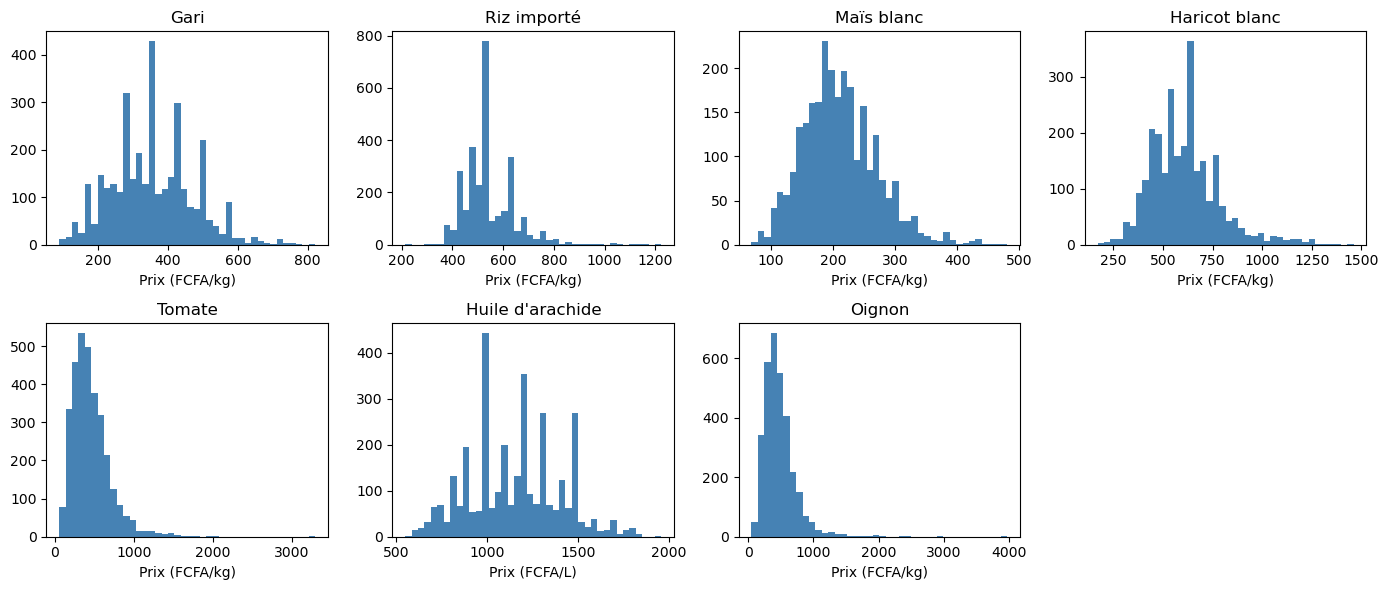

In [29]:
fig, axes = plt.subplots(2, 4, figsize=(14, 6))
axes = axes.flatten()

for ax, p in zip(axes, produits):
    ax.hist(df[df["produit"] == p]["price"], bins=40, color="steelblue")
    ax.set_title(p)
    ax.set_xlabel("Prix (FCFA/L)" if p == "Huile d'arachide" else "Prix (FCFA/kg)")

axes[7].axis("off")
plt.tight_layout()
plt.savefig("../reports/figures/1_1_distribution_prix.png", dpi=150)
plt.show()

**Ce que dit la figure.** Les prix du gari, du maïs, du riz, du haricot et de l'huile forment une cloche resserrée autour de leur médiane : 99 % des prix restent sous 2 fois la médiane (1,5 fois pour l'huile). La tomate et l'oignon s'étalent beaucoup plus, avec une queue qui part très loin à droite (99 % sous 3,3 et 3,2 fois la médiane, mais un maximum à 8 et 9 fois). On travaillera donc sur le log du prix, au moins pour la tomate et l'oignon. Le maximum de l'oignon (3 972 FCFA/kg, Natitingou, juillet 2025) reste à vérifier.

## 1.2 De combien le prix change-t-il d'un mois à l'autre ?

Il faut d'abord remettre chaque série sur un calendrier mensuel complet (86 mois, de janvier 2019 à février 2026). Sinon, un écart de trois mois serait compté comme une variation d'un mois. On met donc les séries en colonnes, une ligne par mois, et un mois sans relevé devient une case vide. La variation en % est vide dès qu'un des deux mois est vide.

In [30]:
prix_large = df.pivot_table(index="mois", columns=["commodity", "market"], values="price")
tous_mois = pd.period_range("2019-01", "2026-02", freq="M")
prix_large = prix_large.reindex(tous_mois)

variation = prix_large.pct_change(fill_method=None) * 100

var_long = variation.stack(["commodity", "market"]).dropna().reset_index()
var_long.columns = ["mois", "commodity", "market", "variation"]
var_long["produit"] = var_long["commodity"].map(noms)

print(prix_large.shape)
print("cases vides :", prix_large.isna().sum().sum())
print("variations calculées :", len(var_long))

(86, 313)
cases vides : 5524
variations calculées : 18074


C:\Users\User\AppData\Local\Temp\ipykernel_25220\1101953778.py:7: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  var_long = variation.stack(["commodity", "market"]).dropna().reset_index()


**Conclusion.** Sur le calendrier complet, 5 524 cases sont vides sur 26 918 (environ 20 %). Cela vient des séries qui commencent tard et des mois manquants. On peut calculer 18 074 variations sur 21 394 relevés : on en perd 313 (le premier mois de chaque série) et environ 3 000 à cause des trous.

Le tableau : `describe` de la variation par produit, la moyenne des variations sans le signe (l'erreur qu'on ferait en disant « le prix ne change pas »), et la part des mois où le prix bouge de plus de 10 %.

In [31]:
resume = var_long.groupby("produit")["variation"].describe().round(1).loc[produits]
absolue = var_long["variation"].abs()
resume["variation moyenne sans signe"] = absolue.groupby(var_long["produit"]).mean().round(1)
resume["part > 10 % (en %)"] = (absolue > 10).groupby(var_long["produit"]).mean().mul(100).round(0)
resume

,count,mean,std,min,25%,50%,75%,max,variation moyenne sans signe,part > 10 % (en %)
produit,,,,,,,,,,
Gari,2950.0,1.1,12.2,-40.0,-4.5,0.0,5.3,116.4,7.7,30.0
Riz importé,2440.0,0.3,7.2,-47.2,0.0,0.0,0.0,98.0,3.2,10.0
Maïs blanc,2184.0,0.5,13.3,-69.5,-5.3,0.0,6.3,75.0,8.7,33.0
Haricot blanc,2259.0,1.1,13.2,-54.3,-4.0,0.0,5.8,190.0,8.0,27.0
Tomate,2760.0,6.6,47.0,-84.8,-16.8,0.2,20.8,1204.3,27.9,69.0
Huile d'arachide,2810.0,0.7,8.1,-45.2,-2.2,0.0,2.5,71.9,4.5,13.0
Oignon,2671.0,5.5,42.0,-87.1,-11.1,0.5,16.0,916.9,20.9,59.0


**Ce que dit le tableau.** Le prix change peu d'un mois à l'autre pour le riz (3,2 % en moyenne sans le signe, 10 % des mois à plus de 10 %) et pour l'huile (4,5 % ; 13 %). Il bouge beaucoup plus pour le gari, le haricot et le maïs (environ 8 % ; 27 à 33 %), et énormément pour l'oignon (20,9 % ; 59 %) et la tomate (27,9 % ; 69 %). La médiane est à 0 pour presque tous : très souvent, le prix ne change pas. Le modèle « le prix ne change pas » se trompera donc d'environ 3 % sur le riz, mais de 20 à 28 % sur l'oignon et la tomate.

Les histogrammes de la variation, un par produit. Une poignée de variations sont énormes (jusqu'à +1 200 % pour la tomate), alors on limite l'axe à ±60 % pour voir le centre.

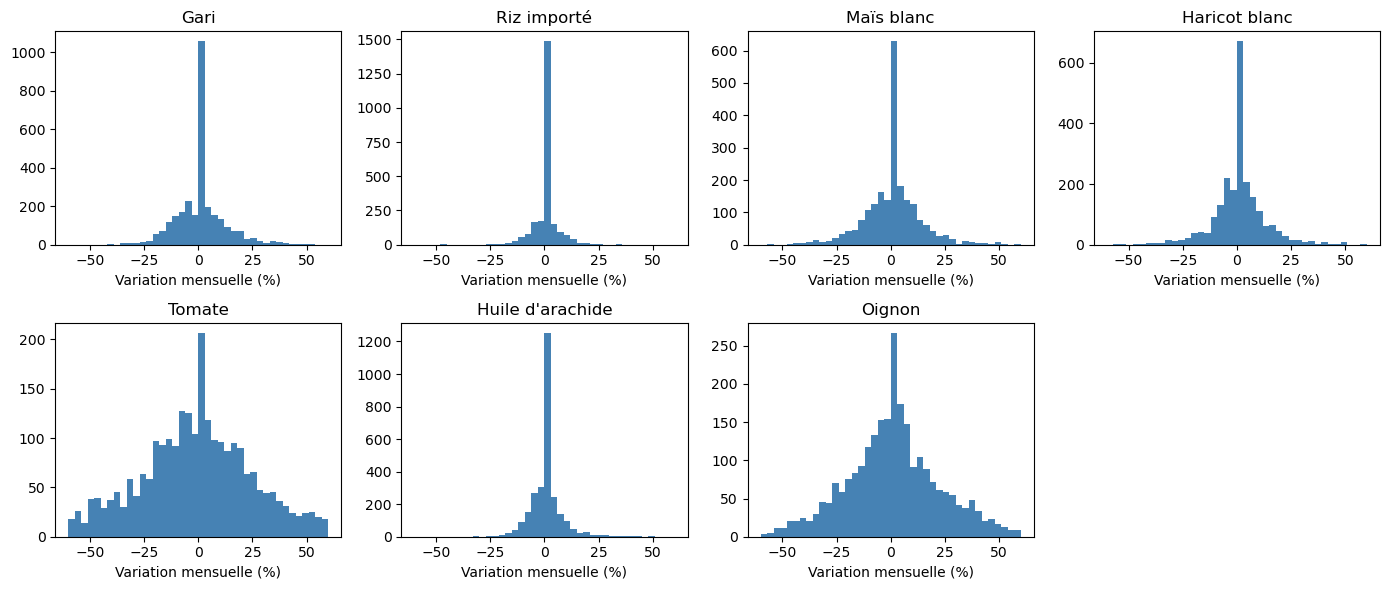

In [32]:
fig, axes = plt.subplots(2, 4, figsize=(14, 6))
axes = axes.flatten()

for ax, p in zip(axes, produits):
    ax.hist(var_long[var_long["produit"] == p]["variation"], bins=40, range=(-60, 60), color="steelblue")
    ax.set_title(p)
    ax.set_xlabel("Variation mensuelle (%)")

axes[7].axis("off")
plt.tight_layout()
plt.savefig("../reports/figures/1_2_variation_mensuelle.png", dpi=150)
plt.show()

**Ce que dit la figure.** Tous les produits ont un grand pic à 0 : c'est le prix qui reste identique d'un mois à l'autre. Le riz et l'huile sont très resserrés autour de 0, alors que la tomate et l'oignon forment une courbe large qui s'étale sur toute la plage. Sur 18 074 variations, 416 dépassent ±60 % (269 pour la tomate, 123 pour l'oignon), et ce sont presque les seules. À garder en tête pour l'erreur du modèle sur ces deux produits.

## 1.3 Combien de séries sont relevées chaque mois ?

Sur le calendrier complet, on compte combien de séries ont un prix chaque mois. Les creux de la courbe seront des mois où il manquera des prix passés.

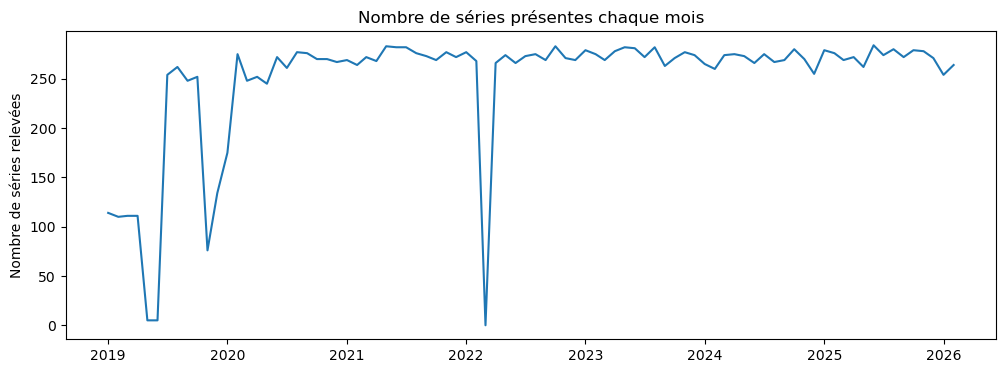

2019-01-01    114
2019-02-01    110
2019-03-01    111
2019-04-01    111
2019-05-01      5
2019-06-01      5
2019-09-01    248
2019-11-01     76
2019-12-01    134
2020-01-01    175
2020-03-01    248
2020-05-01    245
2022-03-01      0
dtype: int64

In [33]:
par_mois = prix_large.notna().sum(axis=1)
par_mois.index = par_mois.index.to_timestamp()

plt.figure(figsize=(12, 4))
plt.plot(par_mois)
plt.ylabel("Nombre de séries relevées")
plt.title("Nombre de séries présentes chaque mois")
plt.savefig("../reports/figures/1_3_series_par_mois.png", dpi=150)
plt.show()

par_mois[par_mois < 250]

**Conclusion.** Depuis 2020, on a environ 270 séries par mois sur 313 (maximum 284). Les trous sont tous au début ou isolés : 110 séries début 2019, seulement 5 en mai et juin 2019, 76 en novembre 2019, et **aucun relevé en mars 2022**. Sur 86 mois, 13 sont sous 250 séries. À cause de mars 2022, les décalages de 1, 2 et 3 mois manquent pour avril, mai et juin 2022, et celui de 12 mois pour mars 2023. Il faudra aussi se méfier de 2019, trop pauvre.

## 1.4 Les marchés couvrent-ils bien le pays ?

On compte les marchés et les séries de chaque département (`admin1`), du nord au sud avec la latitude moyenne.

In [34]:
marches = df.drop_duplicates("market")
dep = marches.groupby("admin1").agg(marches=("market", "nunique"), latitude=("latitude", "mean")).round(2)

series = df.drop_duplicates(["commodity", "market"])
dep["séries"] = series.groupby("admin1").size()

dep.sort_values("latitude", ascending=False)

,marches,latitude,séries
admin1,,,
Alibori,3,11.74,20
Atakora,5,10.49,30
Borgou,6,9.84,37
Donga,3,9.46,19
Collines,4,8.04,28
Zou,6,7.15,39
Plateau,5,6.98,29
Couffo,3,6.94,18
Atlantique,7,6.68,46


**Conclusion.** Les 12 départements sont présents (50 marchés, 313 séries). Le nord (Alibori, Atakora, Borgou, Donga) compte 17 marchés et 106 séries, le centre et le sud 33 marchés et 207 séries : on peut comparer le nord et le sud. Par contre, le Mono et le Littoral n'ont qu'un marché chacun (5 et 7 séries), donc leur « département » n'est que ce marché.

## Bilan de la partie 1

- Les prix du gari, du maïs, du riz, du haricot et de l'huile sont équilibrés autour de leur médiane. La tomate et l'oignon ont une longue queue de prix élevés : on passera au log pour eux.
- Le prix change peu d'un mois à l'autre pour le riz (3 % en moyenne) et l'huile (4,5 %), beaucoup pour la tomate (28 %) et l'oignon (21 %). Le modèle naïf se trompera surtout sur ces deux produits.
- Environ 35 % des variations mensuelles dépassent 10 %, et 69 % pour la tomate.
- Le calendrier complet a 20 % de cases vides : les décalages devront accepter des valeurs manquantes.
- Aucun relevé en mars 2022, et très peu en 2019 : les décalages sont impossibles autour de mars 2022, et on se méfiera de 2019.
- Les 12 départements sont couverts, mais le Mono et le Littoral n'ont qu'un marché chacun.
- À vérifier : le maximum de l'oignon (3 972 FCFA/kg) et les variations extrêmes de la tomate et de l'oignon.

# Partie 2 – Analyse bivariée

On croise le prix avec une autre variable : le temps, le mois de l'année, le lieu ou le prix passé. C'est la partie qui sert à repérer les tendances et les périodes de variation.

## 2.1 Comment les prix ont-ils évolué depuis 2019, et quand ont-ils le plus monté ?

Pour chaque produit, on prend la médiane nationale de chaque mois (et pas la moyenne, que quelques marchés très chers tireraient vers le haut). Puis on ramène chaque produit à 100 en janvier 2019 pour les mettre sur une même figure. Attention : janvier 2019 ne compte que 114 séries, c'est un point de départ fragile.

In [35]:
mediane_nat = df.groupby(["mois", "produit"])["price"].median().unstack()[produits]
mediane_nat = mediane_nat.reindex(prix_large.index)
indice = mediane_nat / mediane_nat.iloc[0] * 100

hausse = pd.DataFrame({
    "prix janv. 2019": mediane_nat.iloc[0].round(0),
    "prix fév. 2026": mediane_nat.iloc[-1].round(0),
})
hausse["hausse totale (%)"] = ((mediane_nat.iloc[-1] / mediane_nat.iloc[0] - 1) * 100).round(0)
hausse["indice maximum"] = indice.max().round(0)
hausse["mois du maximum"] = indice.idxmax().astype(str)
hausse["hausse janv. 2021 à janv. 2022 (%)"] = ((indice.loc["2022-01"] / indice.loc["2021-01"] - 1) * 100).round(0)
hausse

,prix janv. 2019,prix fév. 2026,hausse totale (%),indice maximum,mois du maximum,hausse janv. 2021 à janv. 2022 (%)
produit,,,,,,
Gari,193.0,318.0,65.0,252.0,2024-07,3.0
Riz importé,452.0,532.0,18.0,142.0,2025-02,0.0
Maïs blanc,165.0,153.0,-7.0,197.0,2024-05,19.0
Haricot blanc,435.0,538.0,24.0,219.0,2024-09,37.0
Tomate,328.0,437.0,33.0,269.0,2024-06,31.0
Huile d'arachide,900.0,1200.0,33.0,172.0,2025-01,24.0
Oignon,365.0,435.0,19.0,204.0,2025-01,4.0


**Ce que dit le tableau.** Tous les produits ont monté depuis 2019, sauf le maïs : gari +65 %, tomate et huile +33 %, haricot +24 %, oignon +19 %, riz +18 %, maïs -7 % (de 165 à 153 FCFA/kg). Le choc de 2022 n'a pas touché tout le monde : de janvier 2021 à janvier 2022, haricot +37 %, tomate +31 %, huile +24 %, maïs +19 %, mais gari +3 %, oignon +4 % et riz 0 %. Les sept produits atteignent leur maximum entre mai 2024 et février 2025 (tomate à 269 en juin 2024, gari à 252 en juillet 2024).

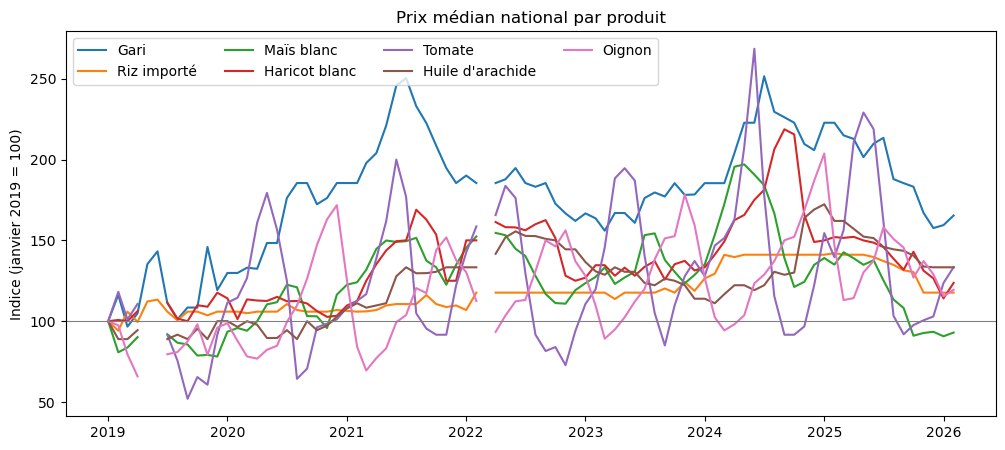

In [36]:
plt.figure(figsize=(12, 5))
x = indice.index.to_timestamp()
for p in produits:
    plt.plot(x, indice[p], label=p)
plt.axhline(100, color="grey", linewidth=0.8)
plt.ylabel("Indice (janvier 2019 = 100)")
plt.title("Prix médian national par produit")
plt.legend(ncol=4)
plt.savefig("../reports/figures/2_1_indice_prix.png", dpi=150)
plt.show()

**Ce que dit la figure.** On voit deux vagues de hausse. La première est en 2021-2022 : entre avril et juin 2022, la tomate monte à 184, le gari à 195, le haricot à 161, le maïs à 155 et l'huile à 156. La seconde est en 2024-2025, plus forte : tous les produits touchent leur maximum. Le riz est la courbe la plus plate (jamais au-dessus de 142). La tomate et l'oignon montent et descendent fortement d'une saison à l'autre. Le trou de mars 2022 vient de l'absence de relevés ce mois-là.

## 2.2 Y a-t-il des saisons ? À quels mois les prix montent-ils ?

Pour chaque série et chaque année, on calcule l'écart du prix à la moyenne de cette année. Sans ça, les marchés chers fausseraient tout. On garde les séries-années avec au moins 10 mois de relevés, puis on fait la moyenne par mois de l'année et par produit.

In [37]:
df["annee"] = df["date"].dt.year
df["mois_annee"] = df["date"].dt.month

cle = ["commodity", "market", "annee"]
nb_mois = df.groupby(cle)["price"].transform("size")
moyenne_annee = df.groupby(cle)["price"].transform("mean")
df["ecart_saison"] = (df["price"] / moyenne_annee - 1) * 100

saison = df[nb_mois >= 10]
print(len(saison), "relevés gardés sur", len(df))

tab_saison = saison.groupby(["produit", "mois_annee"])["ecart_saison"].mean().unstack().loc[produits]
tab_saison.round(1)

14965 relevés gardés sur 21394


mois_annee,1,2,3,4,5,6,7,8,9,10,11,12
produit,,,,,,,,,,,,
Gari,-4.5,-4.6,-6.5,-1.7,0.2,3.6,6.2,6.4,5.1,0.9,-2.8,-3.3
Riz importé,-0.0,-0.1,-0.8,-1.0,-0.1,0.7,0.8,0.9,0.0,0.4,-0.4,-0.5
Maïs blanc,-2.7,0.1,1.8,8.6,9.7,9.4,10.1,4.7,-4.9,-12.8,-14.9,-8.4
Haricot blanc,-6.5,-4.0,-3.6,0.8,2.7,1.8,2.6,6.1,7.8,4.4,-4.7,-8.3
Tomate,-3.4,2.2,2.1,23.3,39.8,43.4,13.6,-23.5,-31.7,-27.8,-24.2,-13.2
Huile d'arachide,-1.7,-2.0,-1.9,-1.7,-1.5,0.4,1.0,0.3,0.2,-0.7,3.0,4.6
Oignon,10.4,-13.5,-25.2,-22.6,-18.1,-9.6,-2.0,4.5,6.5,16.5,26.0,24.2


In [38]:
resume_saison = pd.DataFrame({
    "mois le plus cher": tab_saison.idxmax(axis=1),
    "écart max (%)": tab_saison.max(axis=1).round(1),
    "mois le moins cher": tab_saison.idxmin(axis=1),
    "écart min (%)": tab_saison.min(axis=1).round(1),
})
resume_saison["amplitude (points)"] = (resume_saison["écart max (%)"] - resume_saison["écart min (%)"]).round(1)
resume_saison

,mois le plus cher,écart max (%),mois le moins cher,écart min (%),amplitude (points)
produit,,,,,
Gari,8,6.4,3,-6.5,12.9
Riz importé,8,0.9,4,-1.0,1.9
Maïs blanc,7,10.1,11,-14.9,25.0
Haricot blanc,9,7.8,12,-8.3,16.1
Tomate,6,43.4,9,-31.7,75.1
Huile d'arachide,12,4.6,2,-2.0,6.6
Oignon,11,26.0,3,-25.2,51.2


**Ce que dit le tableau.** La saison est très marquée pour la tomate (+43 % en juin, -32 % en septembre) et l'oignon (+26 % en novembre, -25 % en mars). Elle est nette pour le maïs (+10 % en juillet, -15 % en novembre). Elle est modérée pour le haricot (+8 % en septembre, -8 % en décembre) et le gari (+6 % en août, -6,5 % en mars). Elle est faible pour l'huile (amplitude de 6,6 points) et presque nulle pour le riz importé (1,9 point). On a gardé 14 965 relevés sur 21 394.

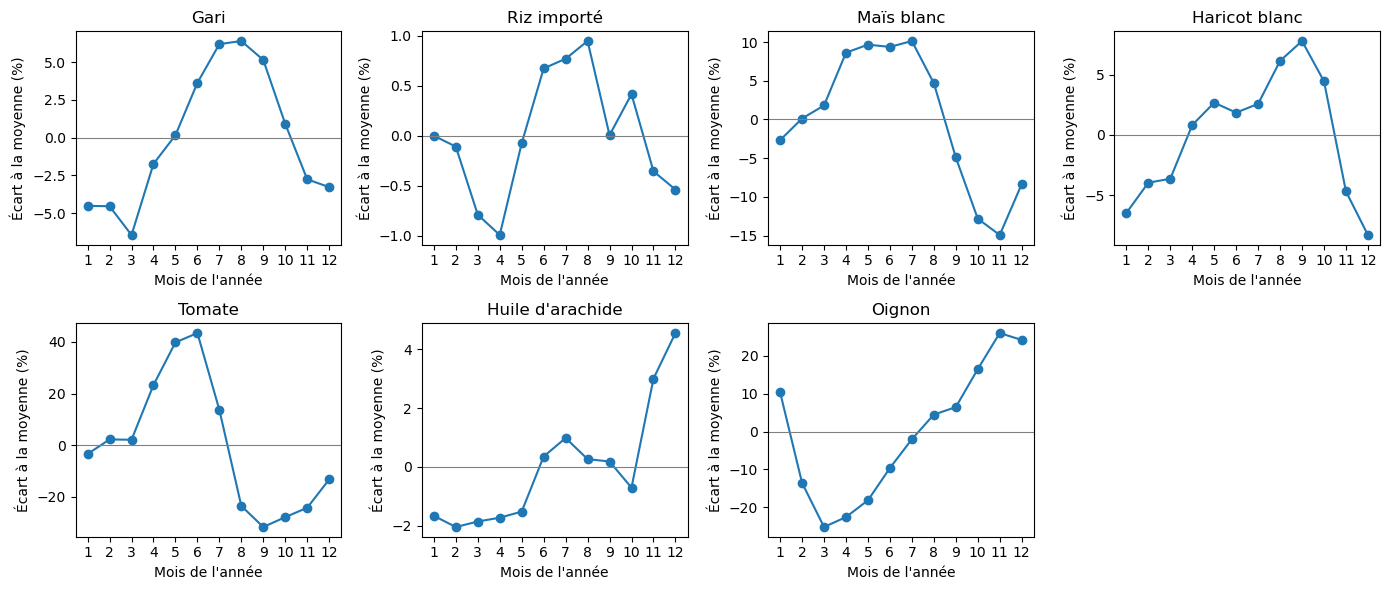

In [39]:
fig, axes = plt.subplots(2, 4, figsize=(14, 6))
axes = axes.flatten()

for ax, p in zip(axes, produits):
    ax.plot(range(1, 13), tab_saison.loc[p], marker="o")
    ax.axhline(0, color="grey", linewidth=0.8)
    ax.set_title(p)
    ax.set_xticks(range(1, 13))
    ax.set_xlabel("Mois de l'année")
    ax.set_ylabel("Écart à la moyenne (%)")

axes[7].axis("off")
plt.tight_layout()
plt.savefig("../reports/figures/2_2_saisonnalite.png", dpi=150)
plt.show()

**Ce que dit la figure.** La tomate et l'oignon sont en miroir : la tomate est chère d'avril à juillet et bon marché d'août à décembre, alors que l'oignon est cher d'août à janvier et bon marché de février à juillet. Pour le maïs, la soudure se voit bien : le prix passe de -3 % en janvier à +9 % en avril et reste haut jusqu'en juillet (+10 %), puis s'effondre après la récolte (-5 % en septembre, -15 % en novembre). Le riz est une ligne plate.

## 2.3 Le lieu change-t-il le prix ?

Comme les produits n'ont pas la même unité ni le même prix, on divise chaque prix par la médiane nationale du même produit le même mois. Un rapport de 1,00 veut dire « au prix médian du pays ». On prend ensuite la médiane de ce rapport par département, du nord au sud (latitude décroissante).

In [40]:
df["med_nat"] = df.groupby(["commodity", "date"])["price"].transform("median")
df["rapport"] = df["price"] / df["med_nat"]

lat_dep = df.drop_duplicates("market").groupby("admin1")["latitude"].mean().sort_values(ascending=False)

par_dep = df.groupby(["admin1", "produit"])["rapport"].median().unstack()[produits].round(2)
par_dep = par_dep.loc[lat_dep.index]
par_dep

produit,Gari,Riz importé,Maïs blanc,Haricot blanc,Tomate,Huile d'arachide,Oignon
admin1,,,,,,,
Alibori,1.24,1.00,0.95,0.80,1.02,1.05,0.89
Atakora,1.13,1.00,0.90,0.97,0.92,1.10,1.14
Borgou,1.19,1.00,0.94,0.93,1.00,1.13,0.71
Donga,1.09,0.98,0.94,1.09,0.88,0.99,1.10
Collines,0.99,1.00,0.88,1.11,1.19,1.07,1.32
Zou,0.87,0.93,1.00,0.94,0.94,0.94,0.86
Plateau,0.84,1.00,0.88,1.09,0.92,1.00,1.02
Couffo,0.62,1.08,1.04,0.71,0.87,0.96,0.99
Atlantique,0.94,0.95,1.11,1.00,1.00,0.92,0.99


**Ce que dit le tableau.** Les écarts entre départements sont parfois grands : le gari va de 0,62 (Couffo) à 1,26 (Mono), l'oignon de 0,71 (Borgou) à 1,32 (Collines), le maïs de 0,88 (Collines, Plateau) à 1,30 (Littoral). Le riz importé reste entre 0,93 et 1,08 partout. Le Mono et le Littoral n'ont qu'un marché chacun, et le Mono n'a ni maïs ni huile : on lit ces deux lignes avec prudence.

Maintenant le prix médian de chaque marché en fonction de sa latitude (un point = un marché), avec la corrélation dans le titre.

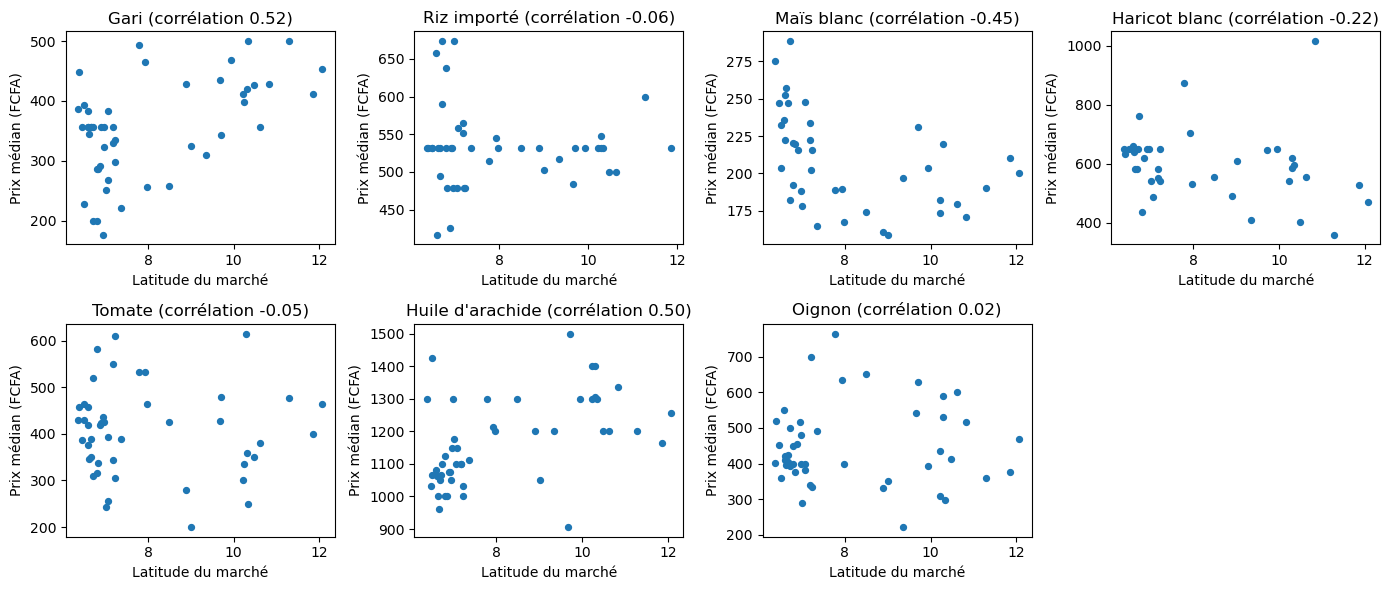

In [41]:
marches_prix = df.groupby(["produit", "market"]).agg(prix=("price", "median"), latitude=("latitude", "first")).reset_index()

fig, axes = plt.subplots(2, 4, figsize=(14, 6))
axes = axes.flatten()

for ax, p in zip(axes, produits):
    g = marches_prix[marches_prix["produit"] == p]
    c = g["prix"].corr(g["latitude"])
    ax.scatter(g["latitude"], g["prix"], s=18)
    ax.set_title(f"{p} (corrélation {c:.2f})")
    ax.set_xlabel("Latitude du marché")
    ax.set_ylabel("Prix médian (FCFA)")

axes[7].axis("off")
plt.tight_layout()
plt.savefig("../reports/figures/2_3_prix_latitude.png", dpi=150)
plt.show()

**Ce que dit la figure.** La latitude compte pour trois produits : le gari (corrélation +0,52) et l'huile (+0,50) sont plus chers au nord, le maïs (-0,45) est moins cher au nord. Pour le haricot (-0,22), le riz (-0,06), la tomate (-0,05) et l'oignon (+0,02), on ne voit pas de lien entre le nord et le sud.

## 2.4 Un marché cher reste-t-il cher ?

On reprend le rapport de 2.3 (prix du marché divisé par la médiane nationale du mois). Pour chaque série, on calcule son rapport moyen sur 2019-2022 puis sur 2023-2026, et on regarde si les deux se ressemblent. On ne garde que les séries avec au moins 12 relevés dans chaque période.

In [42]:
df["periode"] = np.where(df["annee"] <= 2022, "2019-2022", "2023-2026")

groupe = df.groupby(["produit", "market", "periode"])
rapport_moyen = groupe["rapport"].mean().unstack()
nb_releves = groupe.size().unstack()
rapport_moyen = rapport_moyen[(nb_releves >= 12).all(axis=1)].dropna()

print("toutes séries :", round(rapport_moyen["2019-2022"].corr(rapport_moyen["2023-2026"]), 2))
print(rapport_moyen.describe().round(2))

stabilite = rapport_moyen.groupby(level="produit").apply(lambda g: g["2019-2022"].corr(g["2023-2026"])).round(2).loc[produits].to_frame("corrélation entre les deux périodes")
stabilite["nombre de séries"] = rapport_moyen.groupby(level="produit").size()
stabilite

toutes séries : 0.6
periode  2019-2022  2023-2026
count       313.00     313.00
mean          1.04       1.03
std           0.22       0.20
min           0.52       0.46
25%           0.92       0.92
50%           1.00       1.02
75%           1.13       1.13
max           2.51       2.09


,corrélation entre les deux périodes,nombre de séries
produit,,
Gari,0.88,49
Riz importé,0.41,44
Maïs blanc,0.62,40
Haricot blanc,0.87,39
Tomate,0.38,46
Huile d'arachide,0.91,48
Oignon,0.48,47


**Ce que dit le tableau.** Oui pour le gari (corrélation 0,88), le haricot (0,87) et l'huile (0,91) : un marché cher en 2019-2022 l'est aussi en 2023-2026. C'est moyen pour le maïs (0,62), et faible pour l'oignon (0,48), le riz (0,41) et la tomate (0,38). Sur les 313 séries, la corrélation est de 0,60. Pour le riz, les marchés sont tous proches du prix national, donc il y a peu d'écart à retrouver.

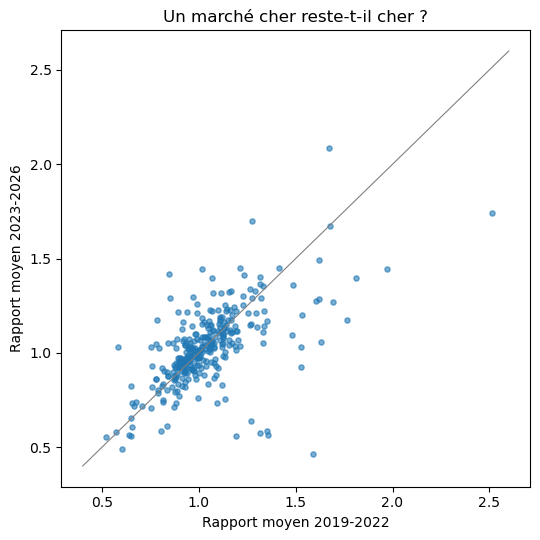

In [43]:
plt.figure(figsize=(5.5, 5.5))
plt.scatter(rapport_moyen["2019-2022"], rapport_moyen["2023-2026"], s=14, alpha=0.6)
plt.plot([0.4, 2.6], [0.4, 2.6], color="grey", linewidth=0.8)
plt.xlabel("Rapport moyen 2019-2022")
plt.ylabel("Rapport moyen 2023-2026")
plt.title("Un marché cher reste-t-il cher ?")
plt.tight_layout()
plt.savefig("../reports/figures/2_4_marche_cher.png", dpi=150)
plt.show()

**Ce que dit la figure.** Les points suivent la diagonale mais le nuage est large. Dans les deux périodes, la moitié des séries ont un rapport entre 0,92 et 1,13, et quelques séries sortent nettement du lot (de 0,52 à 2,51 en 2019-2022). Un écart habituel existe donc, mais seulement pour une partie des produits.

## 2.5 Le prix passé annonce-t-il le prix d'aujourd'hui ?

Sur le calendrier complet, on associe à chaque prix celui du mois d'avant (M-1) et celui d'il y a 12 mois (M-12). On regarde la corrélation par produit, puis les nuages de points.

In [44]:
cles = ["commodity", "market"]
passe = pd.DataFrame({
    "prix": prix_large.stack(cles),
    "m1": prix_large.shift(1).stack(cles),
    "m12": prix_large.shift(12).stack(cles),
}).reset_index()
passe["produit"] = passe["commodity"].map(noms)

lignes = []
for p in produits:
    g = passe[passe["produit"] == p]
    lignes.append({"produit": p, "corrélation avec M-1": g["prix"].corr(g["m1"]), "corrélation avec M-12": g["prix"].corr(g["m12"])})

corr_passe = pd.DataFrame(lignes).set_index("produit").round(2)
corr_passe

C:\Users\User\AppData\Local\Temp\ipykernel_25220\605612118.py:3: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  "prix": prix_large.stack(cles),
C:\Users\User\AppData\Local\Temp\ipykernel_25220\605612118.py:4: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  "m1": prix_large.shift(1).stack(cles),
C:\Users\User\AppData\Local\Temp\ipykernel_25220\605612118.py:5: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new imp

,corrélation avec M-1,corrélation avec M-12
produit,,
Gari,0.93,0.48
Riz importé,0.93,0.55
Maïs blanc,0.87,0.35
Haricot blanc,0.89,0.46
Tomate,0.72,0.51
Huile d'arachide,0.94,0.46
Oignon,0.76,0.47


**Ce que dit le tableau.** Le prix du mois d'avant annonce très bien celui d'aujourd'hui : corrélation de 0,93 à 0,94 pour l'huile, le gari et le riz, 0,87 à 0,89 pour le maïs et le haricot, mais seulement 0,76 pour l'oignon et 0,72 pour la tomate. Le prix d'il y a 12 mois est moins bon (0,35 pour le maïs, jusqu'à 0,55 pour le riz), mais il apporte quand même quelque chose. Ces corrélations sont sur les prix, donc elles contiennent aussi le fait qu'un marché cher reste cher (2.4).

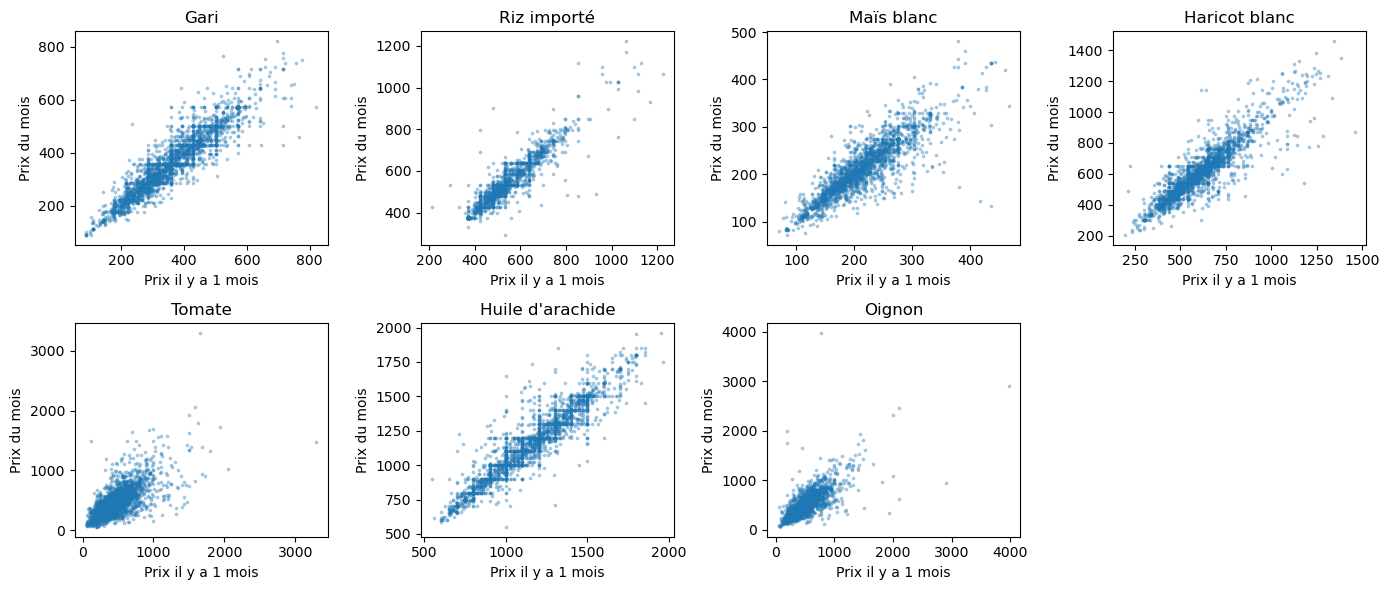

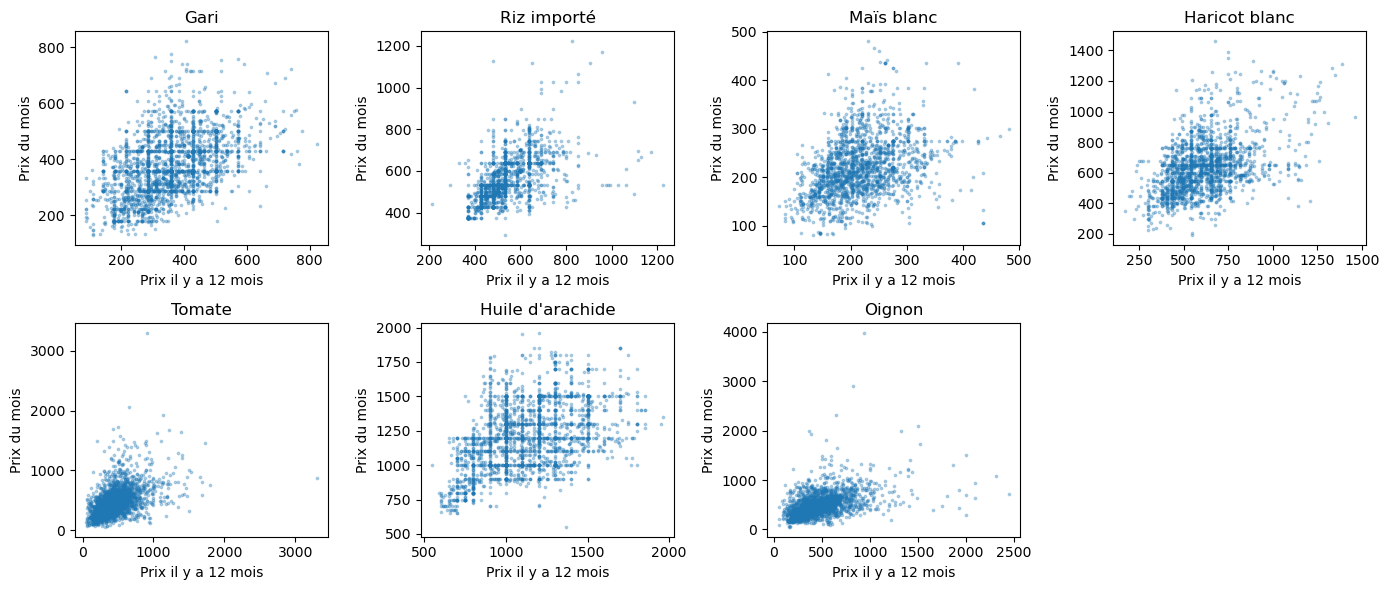

In [45]:
for col, texte, nom_fig in [("m1", "Prix il y a 1 mois", "2_5_prix_m1"), ("m12", "Prix il y a 12 mois", "2_5_prix_m12")]:
    fig, axes = plt.subplots(2, 4, figsize=(14, 6))
    axes = axes.flatten()
    for ax, p in zip(axes, produits):
        g = passe[passe["produit"] == p]
        ax.scatter(g[col], g["prix"], s=3, alpha=0.3)
        ax.set_title(p)
        ax.set_xlabel(texte)
        ax.set_ylabel("Prix du mois")
    axes[7].axis("off")
    plt.tight_layout()
    plt.savefig(f"../reports/figures/{nom_fig}.png", dpi=150)
    plt.show()

**Ce que dit la figure.** Avec M-1, les points forment une ligne serrée pour l'huile, le gari et le riz, et un nuage plus étalé pour la tomate et l'oignon. Avec M-12, les nuages sont beaucoup plus larges pour tous les produits : le prix d'il y a un an donne une idée, pas une valeur précise.

## Bilan de la partie 2

- Deux vagues de hausse : 2021-2022 (haricot +37 %, tomate +31 %, huile +24 %, maïs +19 %, mais pas le riz ni le gari ni l'oignon) et 2024-2025, où les sept produits atteignent leur maximum. L'hypothèse « la hausse de 2022 a touché tous les produits » n'est donc que partiellement vraie.
- Les saisons sont fortes pour la tomate (+43 % en juin, -32 % en septembre) et l'oignon (+26 % en novembre, -25 % en mars), nettes pour le maïs (soudure d'avril à juillet, chute de septembre à novembre), faibles pour le gari, le haricot et l'huile, absentes pour le riz.
- Le lieu compte pour le gari, l'huile (plus chers au nord) et le maïs (moins cher au nord), mais pas pour le riz, la tomate et l'oignon.
- Un marché cher reste cher pour le gari, le haricot et l'huile (corrélation de 0,87 à 0,91), beaucoup moins pour la tomate, le riz et l'oignon (0,38 à 0,48).
- Le prix d'il y a un mois est très informatif (corrélation de 0,72 à 0,94), celui d'il y a 12 mois moins (0,35 à 0,55).

# Partie 3 – Analyse multivariée

On regarde plusieurs variables ensemble : les produits entre eux, les marchés entre eux, et la saison selon le lieu. Pour les corrélations, on utilise les variations mensuelles et pas les prix, sinon la hausse générale des prix gonflerait toutes les corrélations.

## 3.1 Les produits bougent-ils ensemble ?

On prend la variation mensuelle de la médiane nationale de chaque produit, et on calcule les corrélations deux à deux.

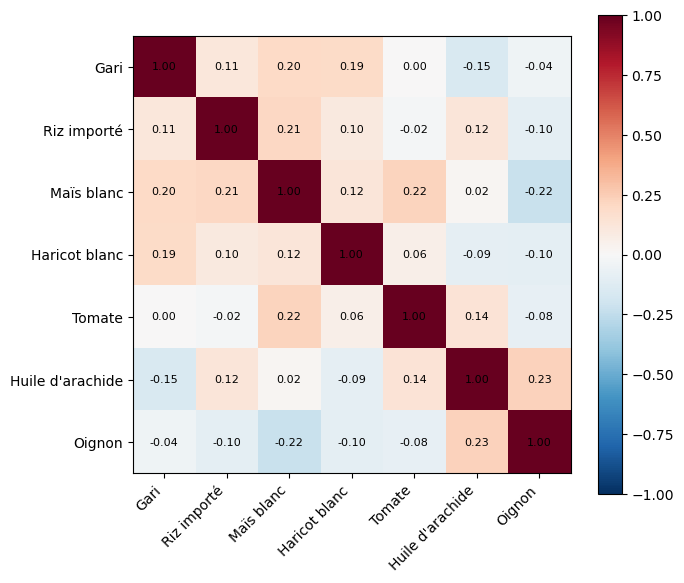

In [46]:
var_produits = mediane_nat.pct_change(fill_method=None) * 100
corr_produits = var_produits.corr().round(2)

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr_produits, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(7))
ax.set_xticklabels(produits, rotation=45, ha="right")
ax.set_yticks(range(7))
ax.set_yticklabels(produits)
for i in range(7):
    for j in range(7):
        ax.text(j, i, f"{corr_produits.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.colorbar(im)
plt.tight_layout()
plt.savefig("../reports/figures/3_1_corr_produits.png", dpi=150)
plt.show()

**Conclusion.** Non, les produits ne bougent presque pas ensemble d'un mois à l'autre : toutes les corrélations sont entre -0,22 et +0,23. Les plus fortes sont huile-oignon (0,23), maïs-tomate (0,22) et maïs-riz (0,21), et la plus négative est maïs-oignon (-0,22). Avec 80 à 83 mois par produit, ces valeurs sont faibles. La variation d'un autre produit n'aide donc pas beaucoup à prévoir.

## 3.2 Les marchés proches bougent-ils ensemble ?

On prend le maïs. Pour chaque paire de marchés (avec au moins 24 mois en commun), on calcule la corrélation de leurs variations mensuelles, et la distance entre eux à partir de la latitude et de la longitude.

In [47]:
from itertools import combinations

def distance_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = np.radians([lat1, lon1, lat2, lon2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

coord = df.drop_duplicates("market").set_index("market")[["latitude", "longitude"]]
corr_mais = variation["Maize (white)"].corr(min_periods=24)

lignes = []
for a, b in combinations(corr_mais.columns, 2):
    if pd.notna(corr_mais.loc[a, b]):
        d = distance_km(coord.loc[a, "latitude"], coord.loc[a, "longitude"], coord.loc[b, "latitude"], coord.loc[b, "longitude"])
        lignes.append({"marche 1": a, "marche 2": b, "distance": d, "corr": corr_mais.loc[a, b]})

paires = pd.DataFrame(lignes)
paires["tranche (km)"] = pd.cut(paires["distance"], [0, 50, 100, 200, 400, 1000])

print(len(paires), "paires de marchés")
paires.groupby("tranche (km)", observed=True)["corr"].agg(["count", "mean"]).round(2)

709 paires de marchés


,count,mean
tranche (km),,
"(0, 50]",123,0.26
"(50, 100]",146,0.29
"(100, 200]",116,0.29
"(200, 400]",190,0.19
"(400, 1000]",134,0.13


**Ce que dit le tableau.** Les marchés proches bougent un peu plus ensemble que les marchés éloignés, mais la corrélation reste faible. Elle est de 0,26 à 0,29 pour les paires à moins de 200 km, de 0,19 entre 200 et 400 km et de 0,13 au-delà de 400 km. On a 709 paires de marchés.

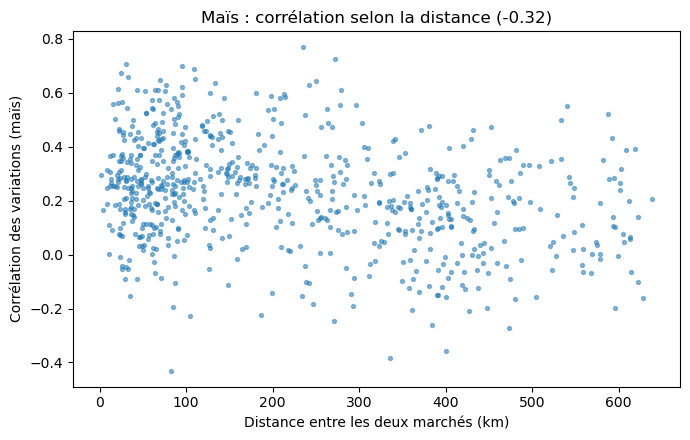

In [48]:
c = paires["corr"].corr(paires["distance"])

plt.figure(figsize=(7, 4.5))
plt.scatter(paires["distance"], paires["corr"], s=8, alpha=0.5)
plt.xlabel("Distance entre les deux marchés (km)")
plt.ylabel("Corrélation des variations (maïs)")
plt.title(f"Maïs : corrélation selon la distance ({c:.2f})")
plt.tight_layout()
plt.savefig("../reports/figures/3_2_corr_distance.png", dpi=150)
plt.show()

**Ce que dit la figure.** Le nuage est très dispersé : à une même distance, certaines paires sont corrélées à 0,5 ou plus et d'autres à 0 ou moins. La corrélation avec la distance est de -0,32 : plus les marchés sont loin, moins ils se ressemblent, mais la distance n'explique qu'une petite partie.

## 3.3 Un marché annonce-t-il les autres ?

Pour chaque produit, on compare la variation d'un mois à Dantokpa (grand marché de Cotonou), puis à Malanville (à la frontière), avec la variation nationale du mois suivant. La variation nationale est la médiane des variations des autres marchés. En première colonne, comme repère : la variation nationale d'un mois contre celle du mois suivant. Les colonnes « mois » donnent le nombre de mois comparés.

In [49]:
lignes = []
for produit, nom in noms.items():
    v = variation[produit]
    nat = v.median(axis=1)
    ligne = {"produit": nom, "national (M vers M+1)": nat.corr(nat.shift(-1))}
    for marche in ["Dantokpa", "Malanville (CBM)"]:
        autres = v.drop(columns=marche).median(axis=1)
        couple = pd.concat([v[marche], autres.shift(-1)], axis=1).dropna()
        ligne[marche] = couple.corr().iloc[0, 1]
        ligne[marche + " (mois)"] = len(couple)
    lignes.append(ligne)

pd.DataFrame(lignes).set_index("produit").round(2)

,national (M vers M+1),Dantokpa,Dantokpa (mois),Malanville (CBM),Malanville (CBM) (mois)
produit,,,,,
Gari,0.45,0.08,81,0.10,74
Riz importé,0.10,0.51,65,-0.01,61
Maïs blanc,0.43,0.10,67,0.23,62
Haricot blanc,0.29,0.29,28,0.61,43
Tomate,0.49,0.41,73,-0.08,73
Huile d'arachide,0.15,0.08,67,-0.11,51
Oignon,0.47,0.39,59,0.53,34


**Conclusion.** Dantokpa et Malanville ne font en général pas mieux que la variation nationale elle-même, qui prévoit déjà le mois suivant à 0,43 à 0,49 pour le gari, le maïs, la tomate et l'oignon. Dantokpa se distingue pour le riz (0,51 contre 0,10 pour le national). Malanville se distingue pour le haricot (0,61 contre 0,29) et l'oignon (0,53), mais sur seulement 43 et 34 mois. Pour le gari, l'huile et la tomate, Malanville n'annonce rien (de -0,11 à 0,10).

## 3.4 La saison est-elle la même au nord et au sud ?

On reprend l'écart saisonnier de 2.2 et on le moyenne par département et par mois, pour la tomate et le maïs. Les départements sont classés du nord (en haut) au sud (en bas). Rouge = prix au-dessus de la moyenne de l'année, bleu = en dessous.

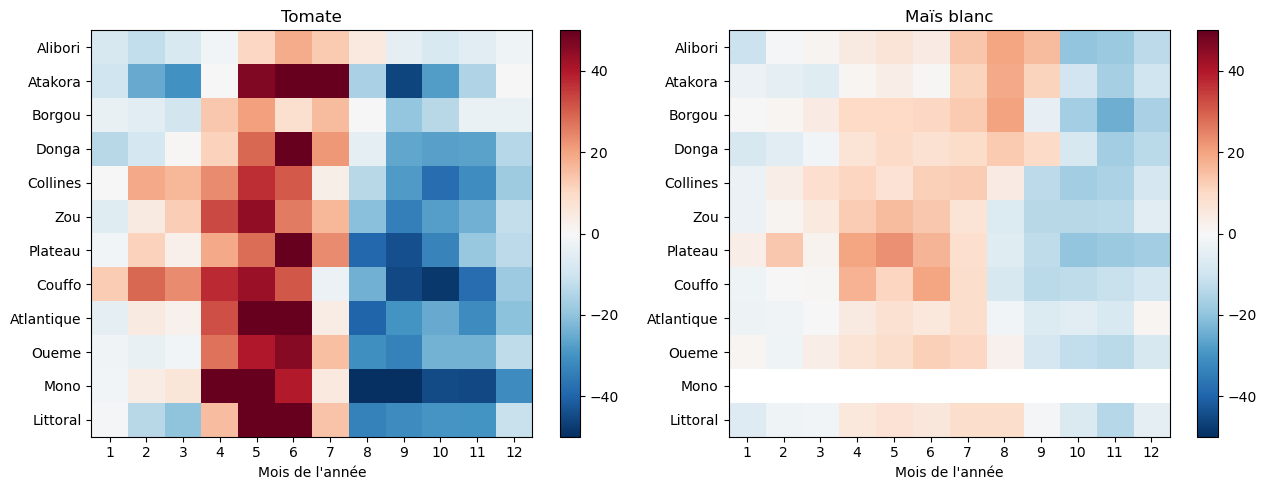

In [50]:
ordre = list(lat_dep.index)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, produit, titre in zip(axes, ["Tomatoes", "Maize (white)"], ["Tomate", "Maïs blanc"]):
    chaleur = saison[saison["commodity"] == produit].groupby(["admin1", "mois_annee"])["ecart_saison"].mean().unstack().reindex(ordre)
    im = ax.imshow(chaleur, cmap="RdBu_r", vmin=-50, vmax=50, aspect="auto")
    ax.set_xticks(range(12))
    ax.set_xticklabels(range(1, 13))
    ax.set_yticks(range(len(ordre)))
    ax.set_yticklabels(ordre)
    ax.set_title(titre)
    ax.set_xlabel("Mois de l'année")
    plt.colorbar(im, ax=ax)

plt.tight_layout()
plt.savefig("../reports/figures/3_4_saison_departement.png", dpi=150)
plt.show()

**Conclusion.** Pour la tomate, la saison est la même partout : le prix est au plus haut en mai ou juin dans les 12 départements et au plus bas entre août et octobre. Seule l'intensité change (+78 % en juin à Atakora, +84 % en mai dans le Mono, mais +18 % en Alibori). Pour le maïs, le calendrier change selon la région : le pic est en août au nord (Alibori +20 %, Borgou +20 %, Atakora +19 %) et d'avril à juin au sud (Plateau +23 % en mai, Couffo +20 % en juin, Zou +16 % en mai). Le creux est en octobre ou novembre partout. Le Mono n'a pas de maïs, et le Mono et le Littoral n'ont qu'un marché.

## 3.5 Combien de mois le passé compte-t-il ?

Pour chaque produit, on mesure si la variation d'un mois ressemble à celle d'il y a 1, 2, … 12 mois. C'est l'autocorrélation, calculée sur toutes les séries du produit ensemble.

In [51]:
decalages = range(1, 13)
auto = {}

for produit, nom in noms.items():
    v = variation[produit]
    valeurs = []
    for k in decalages:
        couple = pd.concat([v.stack(), v.shift(k).stack()], axis=1).dropna()
        valeurs.append(couple.corr().iloc[0, 1])
    auto[nom] = valeurs

auto = pd.DataFrame(auto, index=decalages).round(2)
auto.index.name = "décalage (mois)"
auto

,Gari,Riz importé,Maïs blanc,Haricot blanc,Tomate,Huile d'arachide,Oignon
décalage (mois),,,,,,,
1,-0.09,-0.22,0.04,-0.03,0.01,-0.10,-0.01
2,-0.06,-0.06,-0.04,-0.18,-0.14,-0.06,-0.05
3,0.01,0.00,-0.17,-0.09,-0.13,-0.06,-0.03
4,-0.05,0.03,-0.12,0.00,-0.08,0.01,-0.10
5,-0.04,-0.02,-0.07,-0.00,-0.05,0.05,-0.05
6,-0.01,0.04,-0.07,0.04,-0.01,-0.03,-0.09
7,-0.03,0.00,-0.04,0.03,0.00,-0.01,0.04
8,0.01,-0.00,0.00,-0.05,-0.08,-0.06,-0.07
9,0.09,-0.03,-0.06,-0.07,-0.07,0.01,0.00


**Ce que dit le tableau.** La variation passée d'une série annonce très peu sa variation suivante : toutes les valeurs sont entre -0,22 et +0,25. À 1 mois, c'est proche de 0 (de -0,03 à 0,04) sauf pour le riz (-0,22), l'huile (-0,10) et le gari (-0,09), où une hausse tend à être suivie d'une petite baisse. La seule trace claire est à 11 et 12 mois : maïs (0,19 puis 0,25) et tomate (0,10 puis 0,21), ce qui correspond à la saison.

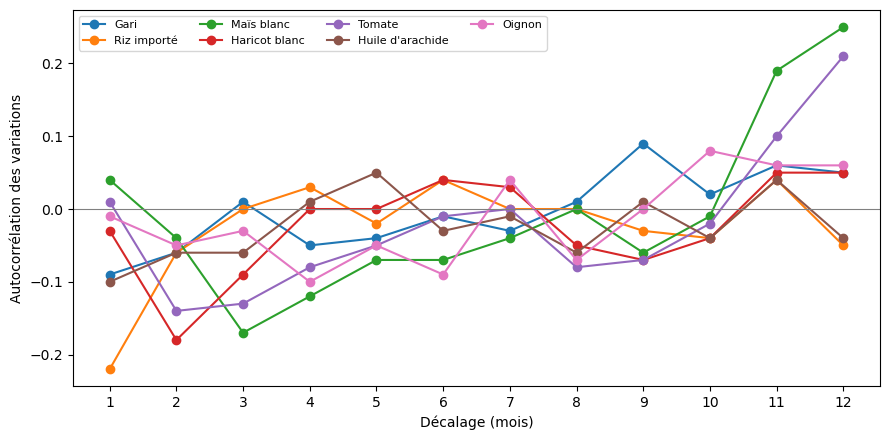

In [52]:
plt.figure(figsize=(9, 4.5))
for p in produits:
    plt.plot(auto.index, auto[p], marker="o", label=p)
plt.axhline(0, color="grey", linewidth=0.8)
plt.xticks(list(decalages))
plt.xlabel("Décalage (mois)")
plt.ylabel("Autocorrélation des variations")
plt.legend(ncol=4, fontsize=8)
plt.tight_layout()
plt.savefig("../reports/figures/3_5_autocorrelation.png", dpi=150)
plt.show()

**Ce que dit la figure.** Toutes les courbes restent autour de 0, sauf la remontée à 11-12 mois pour le maïs et la tomate. Au-delà de 12 mois, on n'a pas besoin de regarder : aucun décalage de 2 à 10 mois n'apporte quelque chose de net. Un contraste est à noter : la variation de la médiane nationale, elle, prévoit celle du mois suivant (0,43 à 0,49 pour quatre produits, voir 3.3), alors que la variation d'une seule série ne le fait pas. Le bruit propre à chaque marché cache l'information.

## Bilan de la partie 3

- Les produits bougent peu ensemble d'un mois à l'autre (corrélations entre -0,22 et 0,23) : la variation d'un autre produit n'aide pas.
- Les marchés proches se ressemblent un peu plus (corrélation du maïs de 0,26 à 0,29 sous 200 km, 0,13 au-delà de 400 km), mais le lien reste faible.
- Dantokpa et Malanville n'annoncent pas mieux que la variation nationale, sauf le riz (Dantokpa) et le haricot (Malanville, sur peu de mois).
- La saison de la tomate est la même partout (pic en mai-juin). Celle du maïs est décalée : août au nord, avril à juin au sud.
- La variation passée d'une série compte très peu (de -0,22 à 0,25), sauf l'écho à 12 mois pour le maïs et la tomate. La variation de la médiane nationale compte davantage (0,43 à 0,49 pour le gari, le maïs, la tomate et l'oignon).

# Partie 4 – Enseignements

On rassemble ce que les parties 2 et 3 ont montré : les périodes de hausse, les saisons de chaque produit, et la liste des variables (features) qui aideront à prévoir le prix du mois suivant. Rien n'est modifié dans les données. Seules les pistes confirmées par un chiffre sont gardées.

## 4.1 Quelles sont les périodes de hausse repérées ?

En 2.1, les courbes de la tomate, de l'oignon et du maïs montent et descendent à chaque saison, ce qui masque les vraies hausses. On lisse donc l'indice : pour chaque mois, on prend la moyenne des 12 derniers mois (une année entière, saisons comprises). Puis on mesure de combien cet indice lissé a monté en 12 mois. Pour chaque produit, on donne la plus forte hausse sur 12 mois et le mois où elle se termine, puis la hausse à fin 2021, fin 2022, fin 2024 et en février 2026 (la dernière). Attention : les hausses qui se terminent en 2020 ou début 2021 s'appuient sur 2019, mal couvert (1.3).

In [53]:
lisse = indice.rolling(12, min_periods=10).mean()
hausse12 = (lisse / lisse.shift(12) - 1) * 100

periodes = pd.DataFrame({
    "plus forte hausse sur 12 mois (%)": hausse12.max().round(0),
    "se termine en": hausse12.idxmax().astype(str),
    "à fin 2021 (%)": hausse12.loc["2021-12"].round(0),
    "à fin 2022 (%)": hausse12.loc["2022-12"].round(0),
    "à fin 2024 (%)": hausse12.loc["2024-12"].round(0),
    "à fév. 2026 (%)": hausse12.loc["2026-02"].round(0),
})
periodes

,plus forte hausse sur 12 mois (%),se termine en,à fin 2021 (%),à fin 2022 (%),à fin 2024 (%),à fév. 2026 (%)
produit,,,,,,
Gari,53.0,2021-06,33.0,-14.0,24.0,-14.0
Riz importé,18.0,2025-01,3.0,7.0,17.0,-7.0
Maïs blanc,34.0,2021-06,30.0,-2.0,20.0,-28.0
Haricot blanc,32.0,2022-03,26.0,9.0,30.0,-21.0
Tomate,35.0,2020-12,8.0,-1.0,7.0,-3.0
Huile d'arachide,33.0,2022-05,27.0,20.0,2.0,4.0
Oignon,32.0,2021-02,-1.0,15.0,2.0,-7.0


**Ce que dit le tableau.** Deux vagues de hausse apparaissent une fois les saisons effacées. **Première vague, qui culmine en 2021-2022** : l'indice lissé monte de 53 % en un an pour le gari (juin 2021), de 34 % pour le maïs (juin 2021), de 32 % pour le haricot (mars 2022) et de 33 % pour l'huile (mai 2022). À fin 2021 : gari +33 %, maïs +30 %, huile +27 %, haricot +26 %, mais riz +3 %, tomate +8 % et oignon -1 %. Le choc de 2022 n'a donc pas touché tous les produits. **Seconde vague, fin 2024** : haricot +30 %, gari +24 %, maïs +20 % et riz +17 % (sa seule vraie hausse, 18 % au plus fort en janvier 2025), alors que l'huile (+2 %), la tomate (+7 %) et l'oignon (+2 %) restent calmes. En février 2026, six produits sur sept sont en baisse sur un an (de -3 % pour la tomate à -28 % pour le maïs) ; seule l'huile monte encore (+4 %). Les hausses de la tomate (35 %, décembre 2020) et de l'oignon (32 %, février 2021) s'appuient sur 2019 : on les lit avec prudence.

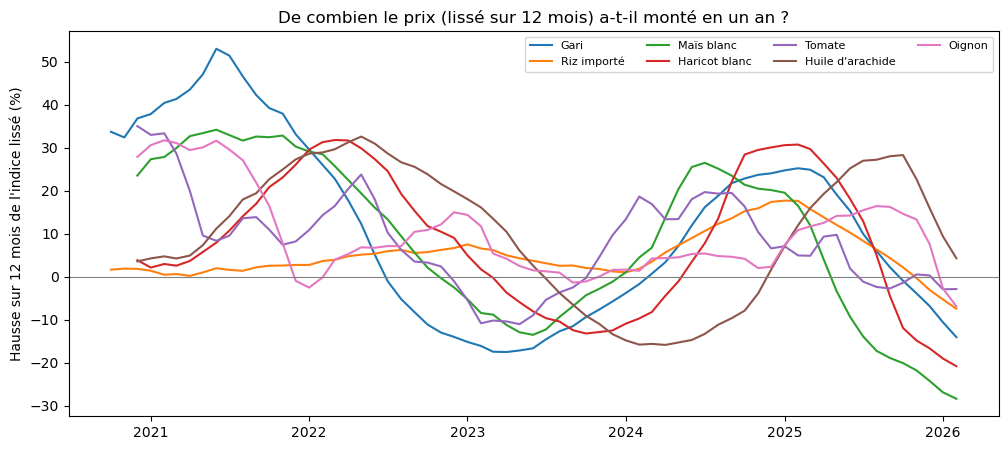

In [54]:
plt.figure(figsize=(12, 5))
x = hausse12.index.to_timestamp()
for p in produits:
    plt.plot(x, hausse12[p], label=p)
plt.axhline(0, color="grey", linewidth=0.8)
plt.ylabel("Hausse sur 12 mois de l'indice lissé (%)")
plt.title("De combien le prix (lissé sur 12 mois) a-t-il monté en un an ?")
plt.legend(ncol=4, fontsize=8)
plt.savefig("../reports/figures/4_1_hausse_12_mois.png", dpi=150)
plt.show()

**Ce que dit la figure.** Les courbes forment deux bosses : l'une entre 2021 et 2022, l'autre entre 2024 et 2025, avec une période de baisse entre les deux (début 2023, le gari est environ 17 % sous son niveau de l'année d'avant). Le riz est la courbe la plus plate et monte plus tard que les autres. L'huile est décalée : son premier sommet est en mai 2022 (+33 %), puis elle fait une seconde bosse tardive (+28 % en octobre 2025) alors que le haricot et le maïs plongent déjà. Après début 2025, tous les produits sauf l'huile redescendent.

## 4.2 Quelles sont les saisons de chaque produit ?

On reprend l'écart saisonnier de 2.2 (prix du mois divisé par la moyenne de l'année de la série). Pour chaque produit, on liste les mois à plus de +10 % (chers) et à moins de -10 % (bon marché). On ajoute la part de la variation des écarts que le seul mois de l'année explique : c'est le chiffre qui dit si connaître le mois suffit à corriger le prix. Elle est calculée avec des moyennes, donc elle est tirée vers le bas par les quelques variations extrêmes de la tomate et de l'oignon.

In [55]:
noms_mois = ["janv.", "fév.", "mars", "avr.", "mai", "juin", "juil.", "août", "sept.", "oct.", "nov.", "déc."]

def liste_mois(ligne, signe, seuil=10):
    choisis = [noms_mois[m - 1] for m in range(1, 13) if signe * ligne[m] >= seuil]
    return ", ".join(choisis) if choisis else "aucun"

def part_expliquee(p):
    s = saison[saison["produit"] == p]["ecart_saison"]
    moyenne_mois = s.groupby(saison.loc[s.index, "mois_annee"]).transform("mean")
    return (1 - ((s - moyenne_mois) ** 2).sum() / ((s - s.mean()) ** 2).sum()) * 100

def force(amplitude):
    if amplitude >= 50: return "très forte"
    if amplitude >= 20: return "nette"
    if amplitude >= 10: return "modérée"
    return "faible"

saisons_produit = pd.DataFrame({
    "mois chers (> +10 %)": [liste_mois(tab_saison.loc[p], +1) for p in produits],
    "mois bon marché (< -10 %)": [liste_mois(tab_saison.loc[p], -1) for p in produits],
    "amplitude (points)": resume_saison["amplitude (points)"].values,
    "saison": [force(a) for a in resume_saison["amplitude (points)"]],
    "part expliquée par le mois (%)": [round(part_expliquee(p), 0) for p in produits],
}, index=produits)
saisons_produit

,mois chers (> +10 %),mois bon marché (< -10 %),amplitude (points),saison,part expliquée par le mois (%)
Gari,aucun,aucun,12.9,modérée,10.0
Riz importé,aucun,aucun,1.9,faible,1.0
Maïs blanc,juil.,"oct., nov.",25.0,nette,26.0
Haricot blanc,aucun,aucun,16.1,modérée,12.0
Tomate,"avr., mai, juin, juil.","août, sept., oct., nov., déc.",75.1,très forte,38.0
Huile d'arachide,aucun,aucun,6.6,faible,4.0
Oignon,"janv., oct., nov., déc.","fév., mars, avr., mai",51.2,très forte,25.0


**Ce que dit le tableau.** La saison est **très forte** pour la tomate (chère d'avril à juillet, bon marché d'août à décembre) et pour l'oignon (cher d'octobre à janvier, bon marché de février à mai). Elle est **nette** pour le maïs (cher en juillet, bon marché en octobre-novembre), **modérée** pour le haricot (16 points) et le gari (13 points), **faible** pour l'huile (7 points) et le riz (2 points). Pour le gari, le riz, le haricot et l'huile, aucun mois ne dépasse ±10 %. Le mois de l'année explique 38 % de la variation de l'écart pour la tomate, 26 % pour le maïs et 25 % pour l'oignon, mais seulement 10 à 12 % pour le gari et le haricot, 4 % pour l'huile et 1 % pour le riz. Même pour la tomate, plus de la moitié de la variation vient donc d'autre chose que du mois. Pour le maïs, ces mois valent pour tout le pays : le calendrier est décalé entre le nord (pic en août) et le sud (avril à juin), voir 3.4.

## 4.3 Quelles features garder ?

On passe en revue chaque piste des parties 2 et 3. Pour deux d'entre elles, les résultats précédents ne répondent pas tout à fait à la question « est-ce utilisable pour prévoir le mois M ? », donc on vérifie d'abord :

- **La variation nationale du mois d'avant.** En 3.3, on a comparé la variation nationale à la variation nationale du mois suivant. Ici, on compare la variation nationale du mois M-1 à la variation de chaque série au mois M.
- **Les marchés voisins.** En 3.2, les corrélations sont calculées sur le même mois, donc on ne pourrait pas s'en servir pour prévoir. On regarde la variation moyenne des marchés à moins de 100 km, au mois M-1, contre la variation de chaque série au mois M. On vérifie aussi si les voisins apportent quelque chose en plus de la variation nationale (colonne « voisins en plus du national » : corrélation une fois enlevé ce que le national explique).

On utilise la corrélation de rang (Spearman), qui ne se laisse pas tirer par les variations extrêmes de la tomate et de l'oignon.

In [56]:
def en_long(w):
    return w.rename_axis(index="mois", columns="market").unstack()

def sans(y, z):
    # ce qui reste de y une fois enlevé ce que z explique (droite de régression)
    return y - np.polyval(np.polyfit(z, y, 1), z)

lignes = []
for produit, nom in noms.items():
    v = variation[produit]

    # variation nationale du mois M-1 (médiane des marchés, si au moins 10 séries du produit)
    nat = v.median(axis=1).where(v.notna().sum(axis=1) >= 10)
    nat_m1 = (v * 0).add(nat.shift(1), axis=0)

    # variation moyenne des marchés à moins de 100 km, au mois M-1
    voisins = pd.DataFrame(index=v.index, columns=v.columns, dtype=float)
    for m in v.columns:
        proches = [k for k in v.columns if k != m and distance_km(*coord.loc[m], *coord.loc[k]) < 100]
        if proches:
            voisins[m] = v[proches].mean(axis=1)

    t = pd.concat([en_long(v), en_long(nat_m1), en_long(voisins.shift(1))], axis=1, keys=["propre", "nat", "voisins"]).dropna()
    r = t.rank()  # corrélation de Pearson sur les rangs = corrélation de Spearman
    lignes.append({
        "produit": nom,
        "variation nationale M-1": r["propre"].corr(r["nat"]),
        "marchés voisins M-1": r["propre"].corr(r["voisins"]),
        "corrélation entre les deux": r["nat"].corr(r["voisins"]),
        "voisins en plus du national": np.corrcoef(sans(r["propre"], r["nat"]), sans(r["voisins"], r["nat"]))[0, 1],
        "nombre de couples": len(t),
    })

verif = pd.DataFrame(lignes).set_index("produit").round(2)
verif

,variation nationale M-1,marchés voisins M-1,corrélation entre les deux,voisins en plus du national,nombre de couples
produit,,,,,
Gari,0.16,0.19,0.63,0.12,2809
Riz importé,0.04,0.11,0.22,0.11,2185
Maïs blanc,0.31,0.29,0.76,0.09,2026
Haricot blanc,0.15,0.15,0.61,0.08,2122
Tomate,0.27,0.23,0.77,0.04,2509
Huile d'arachide,0.15,0.17,0.43,0.12,2645
Oignon,0.26,0.23,0.69,0.07,2506


**Ce que dit le tableau.** La variation nationale du mois d'avant annonce un peu la variation de chaque série au mois M pour le maïs (0,31), la tomate (0,27) et l'oignon (0,26), un peu moins pour le gari, le haricot et l'huile (0,15 à 0,16), et presque pas pour le riz (0,04). C'est plus faible que les 0,43 à 0,49 de 3.3, ce qui est normal : ici on prévoit une série avec son bruit propre, pas une médiane nationale. Les marchés voisins donnent des valeurs du même ordre (0,11 à 0,29), mais ils disent en grande partie la même chose que le national : les deux sont corrélés entre eux (0,61 à 0,77 pour le gari, le maïs, le haricot, la tomate et l'oignon ; 0,43 pour l'huile ; 0,22 pour le riz). Une fois enlevé le national, les voisins n'ajoutent que 0,04 à 0,09 pour le maïs, la tomate, l'oignon et le haricot, et 0,11 à 0,12 pour le gari, le riz et l'huile. On garde donc la variation nationale (plus simple, et disponible même pour un marché isolé) et on met les voisins de côté, à retester en modélisation.

### Tableau des features

Convention : on prévoit le prix du mois M, et chaque feature n'utilise que des mois **avant M**.

| Feature | Définition | Ce qui la justifie | Décision |
|---|---|---|---|
| `prix_m1` | Prix de la série au mois M-1 | 2.5 : corrélation avec le prix du mois de 0,93 à 0,94 (huile, gari, riz), 0,87 à 0,89 (maïs, haricot), 0,72 à 0,76 (tomate, oignon) | **Gardée** |
| `prix_m12` | Prix de la série au mois M-12 | 2.5 : corrélation de 0,35 à 0,55 ; 3.5 : écho à 12 mois de la variation pour le maïs (0,25) et la tomate (0,21) | **Gardée** |
| `prix_dernier_connu`, `anciennete_dernier_prix` | Dernier prix connu dans les 3 mois avant M, et son âge en mois | 1.3 et 1.2 : 20 % de cases vides. Le prix M-1 manque pour 15,5 % des lignes ; avec le dernier prix connu il n'en reste que 2,8 % sans repère | **Gardées** |
| `med_nat_m1` | Médiane nationale du produit au mois M-1 | 2.1 et 3.3 : les prix bougent par vagues nationales. Avec `ecart_marche`, donne une estimation quand le prix de la série manque | **Gardée** (à confirmer en modélisation) |
| `var_nat_m1` | Variation de la médiane nationale entre M-2 et M-1 | 3.3 : la variation nationale prévoit celle du mois suivant (0,43 à 0,49 pour gari, maïs, tomate, oignon) ; 4.3 : corrélation de rang avec la variation de la série au mois M de 0,26 à 0,31 pour le maïs, la tomate et l'oignon, et de 0,15 à 0,16 pour le gari, le haricot et l'huile | **Gardée** |
| `ecart_marche` | Rapport moyen du prix du marché au prix national, sur les mois avant M | 2.4 : un marché cher reste cher pour le gari (0,88), le haricot (0,87) et l'huile (0,91), moins pour le maïs (0,62), l'oignon (0,48), le riz (0,41) et la tomate (0,38) | **Gardée** |
| `mois_annee` | Mois de l'année de M (1 à 12) | 2.2 : amplitude de 75 points pour la tomate, 51 pour l'oignon, 25 pour le maïs ; 4.2 : le mois explique 38 % de la variation de l'écart saisonnier pour la tomate, 26 % pour le maïs et 25 % pour l'oignon | **Gardée** |
| `latitude` | Latitude du marché | 2.3 : corrélation avec le prix de +0,52 (gari), +0,50 (huile), -0,45 (maïs) | **Gardée** |
| `nord` | 1 si le marché est en Alibori, Atakora, Borgou ou Donga | 3.4 : la saison du maïs est décalée (pic en août au nord, d'avril à juin au sud) ; la tomate est la même partout | **Gardée** |
| Prix des marchés voisins | Variation des marchés à moins de 100 km, au mois M-1 | 3.2 : lien faible, et calculé sur le même mois ; 4.3 : du même ordre que la variation nationale (0,11 à 0,29) mais en grande partie redondant avec elle (corrélation de 0,61 à 0,77 entre les deux pour 5 produits sur 7) ; à retester en modélisation | Écartée pour l'instant |
| Prix de Dantokpa ou de Malanville | Prix d'un marché de référence au mois M-1 | 3.3 : ne fait pas mieux que la variation nationale, sauf le riz (Dantokpa) et le haricot (Malanville, sur 43 mois) | Écartée |
| Variation d'un autre produit | Variation du mois M-1 des autres produits | 3.1 : corrélations entre -0,22 et +0,23 | Écartée |
| Décalages de 2 à 10 mois | Prix ou variation à M-2 … M-10 | 3.5 : autocorrélation entre -0,18 et +0,09, rien de net | Écartée |
| Département (`admin1`) | Département du marché | Redondant avec `latitude` et `nord`, et le Mono et le Littoral n'ont qu'un marché (1.4) | Écartée (gardé comme colonne d'information) |

Deux choix de traitement, pour la partie 5 :

- **Les trous.** On ne remplit jamais `prix_m1` ou `prix_m12` : un prix manquant reste vide. À la place, `prix_dernier_connu` et son âge donnent un repère quand M-1 manque.
- **Les mois trop pauvres.** La médiane nationale d'un produit n'est calculée que si le mois a au moins 10 séries de ce produit (1.3 : un produit en a en général 30 à 45 par mois, mais mai-juin 2019 n'en ont que 5 en tout et mars 2022 aucune). Ces mois-là, et le mois suivant pour `var_nat_m1`, donnent des valeurs vides pour `med_nat_m1` et `var_nat_m1`.

## Bilan de la partie 4

- **Deux vagues de hausse.** La première culmine en 2021-2022 : à fin 2021, gari +33 %, maïs +30 %, huile +27 %, haricot +26 %, mais pas le riz (+3 %), la tomate (+8 %) ni l'oignon (-1 %). La seconde culmine fin 2024 : haricot +30 %, gari +24 %, maïs +20 %, riz +17 %. En février 2026, six produits sur sept baissent sur un an (de -3 % à -28 %), l'huile monte encore (+4 %).
- **Saisons.** Très fortes pour la tomate (75 points d'amplitude) et l'oignon (51), nettes pour le maïs (25), modérées pour le haricot et le gari, faibles pour l'huile, absentes pour le riz. Le mois explique 38 % (tomate), 26 % (maïs) et 25 % (oignon) de l'écart saisonnier, au plus 12 % pour les autres.
- **Features gardées (10 colonnes).** `prix_m1`, `prix_m12`, `prix_dernier_connu`, `anciennete_dernier_prix`, `med_nat_m1`, `var_nat_m1`, `ecart_marche`, `mois_annee`, `latitude`, `nord`.
- **Features écartées.** Marchés voisins (redondants avec le national), prix de Dantokpa ou Malanville, variation des autres produits, décalages de 2 à 10 mois, département.
- **Trous.** Un prix manquant n'est jamais rempli. On donne à la place le dernier prix connu (3 mois au plus) et son âge. Un mois à moins de 10 séries d'un produit n'a pas de médiane nationale pour ce produit.
- **Pour la modélisation.** Le prix du mois d'avant (`prix_m1`) est la référence à battre, surtout pour la tomate et l'oignon, où le prix change de 20 à 28 % par mois en moyenne.